# Cell 1: Dataset Pathing & YAML Generation

In [1]:
import os
import yaml

print("Hunting for the mounted tfp_dataset...")
BASE_KAGGLE_INPUT = "/kaggle/input"
INPUT_DATASET_PATH = None

for root, dirs, files in os.walk(BASE_KAGGLE_INPUT):
    if 'tfp_dataset' in dirs:
        INPUT_DATASET_PATH = os.path.join(root, 'tfp_dataset')
        break 

if not INPUT_DATASET_PATH:
    raise FileNotFoundError("Could not find 'tfp_dataset'. Make sure Notebook A's output is mounted via 'Add Input'.")

print(f"Success! Found dataset at: {INPUT_DATASET_PATH}")

# Generate data.yaml dynamically for the 9 translated classes
yaml_data = {
    'train': f'{INPUT_DATASET_PATH}/train/images',
    'val': f'{INPUT_DATASET_PATH}/val/images',
    'test': f'{INPUT_DATASET_PATH}/test/images',
    'nc': 9,
    'names': ["Car", "Bus", "Truck", "Motorcycle", "Bicycle", "Rickshaw", "Mini-Truck", "CNG", "Pedestrian"]
}

with open('/kaggle/working/data.yaml', 'w') as f:
    yaml.dump(yaml_data, f)
print("data.yaml generated successfully!")

Hunting for the mounted tfp_dataset...
Success! Found dataset at: /kaggle/input/notebooks/sharminaktermukta/data-preparation/tfp_dataset
data.yaml generated successfully!


# Cell 2: RT-DETR Training Execution

In [2]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.6/46.6 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 31.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.8/75.8 kB 4.4 MB/s eta 0:00:00


In [3]:
from ultralytics import RTDETR
import torch

# Clear VRAM before initializing the transformer
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Load the RT-DETR-Large baseline model
print("Initializing RT-DETR-Large Architecture...")
model = RTDETR('rtdetr-l.pt')

print("Starting RT-DETR Training Sequence...")
results = model.train(
    data='/kaggle/working/data.yaml',
    epochs=30,          
    imgsz=640,          
    batch=8,            # Lowered batch size to 8 because Transformers consume more VRAM than YOLO
    save_period=5,      
    project='/kaggle/working/runs', 
    name='rtdetr_tfp_bd',
    
    # Advanced augmentations to assist the Transformer with class imbalance
    mosaic=1.0,          
    mixup=0.2,           
    copy_paste=0.1       
)
print("RT-DETR Training Complete! Weights are securely saved in /kaggle/working/runs/")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Initializing RT-DETR-Large Architecture...
Starting RT-DETR Training Sequence...
Ultralytics 8.4.152 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.1, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4

/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:865: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       1/30      6.66G      0.714     0.6048     0.2131        115        640: 100% ━━━━━━━━━━━━ 2072/2072 1.8it/s 18:60
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 296/296 2.9it/s 1:43
                   all       4736      53115      0.589      0.653      0.657      0.389

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size


/usr/local/lib/python3.12/dist-packages/ray/train/_internal/session.py:676: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/30      7.13G     0.5049     0.5831     0.1263        132        640: 0% ──────────── 0/2072  0.6s

/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:865: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


... (53 outputs left out)

/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:865: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      29/30      7.13G     0.2997     0.4419    0.06793         68        640: 100% ━━━━━━━━━━━━ 2072/2072 1.9it/s 18:36
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 296/296 3.0it/s 1:39
                   all       4736      53115      0.684      0.729      0.752      0.519

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      30/30      7.13G      0.248     0.4003    0.06542         76        640: 0% ──────────── 0/2072  0.6s

/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:865: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      30/30      7.13G     0.2968     0.4371    0.06734         52        640: 100% ━━━━━━━━━━━━ 2072/2072 1.9it/s 18:36
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 296/296 3.0it/s 1:39
                   all       4736      53115      0.681      0.715      0.747      0.517

30 epochs completed in 10.114 hours.
Optimizer stripped from /kaggle/working/runs/rtdetr_tfp_bd/weights/last.pt, 66.2MB
Optimizer stripped from /kaggle/working/runs/rtdetr_tfp_bd/weights/best.pt, 66.2MB

Validating /kaggle/working/runs/rtdetr_tfp_bd/weights/best.pt...
Ultralytics 8.4.152 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
rt-detr-l summary (fused): 315 layers, 32,002,235 parameters, 0 gradients, 105.4 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 296/296 3.2it/s 1:32
                   all       4736      53115      0.692      0.713      0.752      0.519
 

# Cell 3: Generate RT-DETR Thesis Visuals

--- THESIS VISUALS FOR RTDETR_TFP_BD ---

Confusion Matrix:


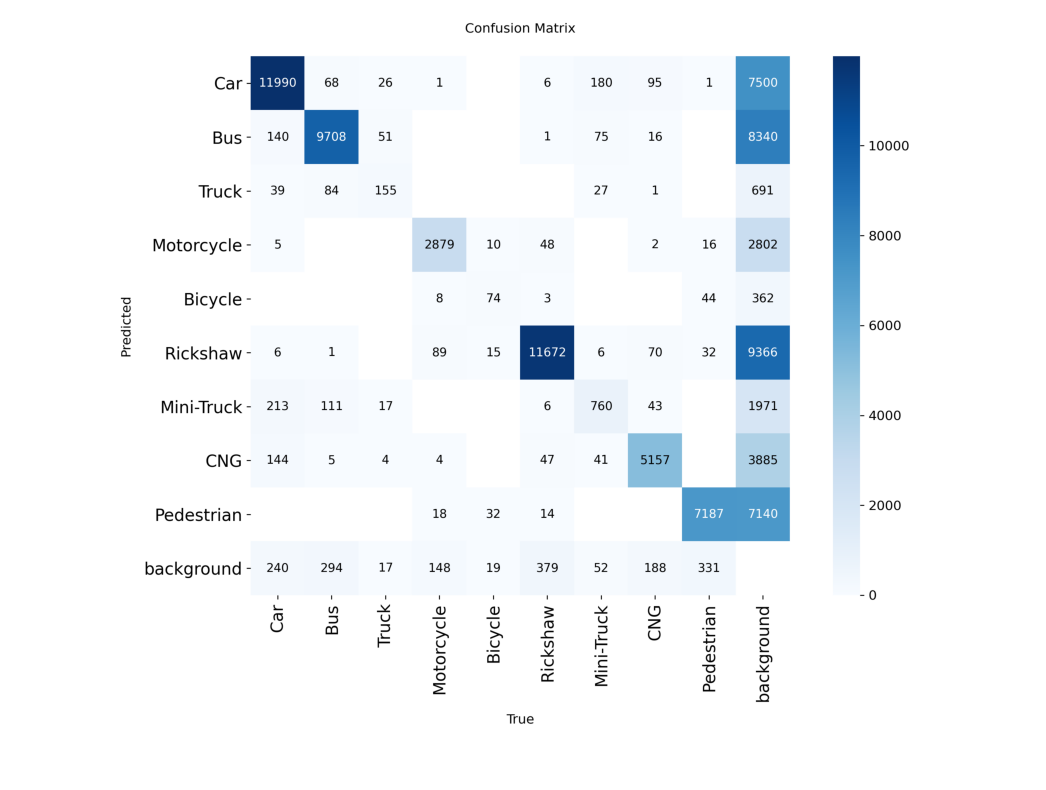


Training Results:


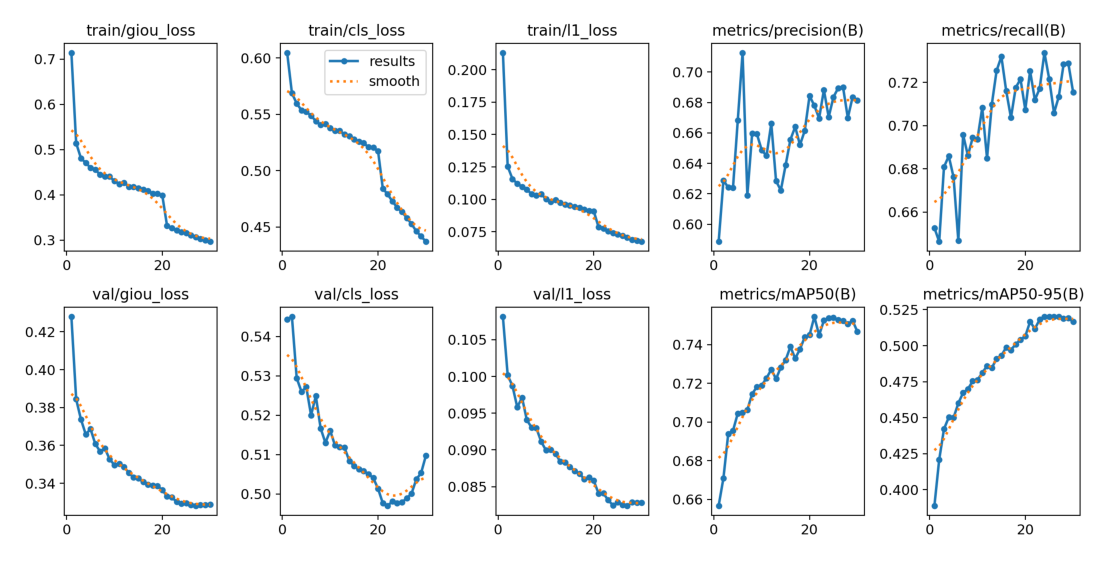

In [4]:
import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

def display_rtdetr_visuals(model_name='rtdetr_tfp_bd'):
    base_path = f'/kaggle/working/runs/{model_name}'
    
    # The 4 most critical plots for a computer vision research paper
    visuals = [
        ('Confusion Matrix', 'confusion_matrix.png'),
        ('Precision-Recall Curve', 'PR_curve.png'),
        ('F1-Confidence Curve', 'F1_curve.png'),
        ('Training Results', 'results.png')
    ]
    
    print(f"--- THESIS VISUALS FOR {model_name.upper()} ---")
    
    for title, filename in visuals:
        img_path = os.path.join(base_path, filename)
        if os.path.exists(img_path):
            print(f"\n{title}:")
            img = mpimg.imread(img_path)
            plt.figure(figsize=(14, 10))
            plt.imshow(img)
            plt.axis('off')
            plt.show()
        else:
            print(f"Warning: {filename} not found. Ensure training completed!")

# Display the visuals
display_rtdetr_visuals()

# 